# EDA 1: day-ahead prices

All seven core zones, read from the config by `group: core`: DE_LU, FR, ES and the four Swedish zones SE_1 to SE_4. Hourly table (experiment H).

All seven zones get the same analysis.

**Train data only.** Every figure and number uses delivery days before `splits.validation_start` (2026-06-23). No validation or test day is read.

How to read this notebook:

- Each code cell calls a function of `epf.eda.price_figures`. The command `python -m epf.eda.price_figures` calls the same functions and writes the figures to `reports/figures/`.
- Each cell prints the tables behind its figure. Every number in a finding below is copied from those tables.
- Prices are in EUR/MWh. Hours, weekdays, months and years are in market time (Europe/Berlin).
- Price levels differ several-fold between zones, so a number in EUR is compared within a zone, not between zones.
- A sentence that starts with "Guess:" is my reading of a cause. The data in this notebook does not test it.

In [1]:
from epf.config import load_config
from epf.eda import price_figures as figures

config = load_config()
prices = figures.load_core_prices(config)
figures.print_tables({"Train data, hourly table": figures.train_period(prices, config)})


Train data, hourly table
       hours        first_hour         last_hour  empty_prices
DE_LU  65519  2019-01-01 00:00  2026-06-22 23:00             0
FR     65519  2019-01-01 00:00  2026-06-22 23:00             0
ES     65519  2019-01-01 00:00  2026-06-22 23:00             0
SE_1   65519  2019-01-01 00:00  2026-06-22 23:00             0
SE_2   65519  2019-01-01 00:00  2026-06-22 23:00             0
SE_3   65519  2019-01-01 00:00  2026-06-22 23:00             0
SE_4   65519  2019-01-01 00:00  2026-06-22 23:00             0


The train set has 65519 hours per zone, from 2019-01-01 00:00 to 2026-06-22 23:00, and no empty price. 2026 is a part year.

## 1. Price distribution


Summary
       hours  mean    std     min    q01  q05   q25  median    q75    q95    q99     max  skew
DE_LU  65519 94.86  91.89 -500.00 -11.57 1.32 38.28   77.10 116.77 272.47 475.36  936.28  2.50
FR     65519 93.71 102.84 -496.86  -2.00 3.09 33.86   62.38 112.30 300.95 510.00 2987.78  3.03
ES     65519 80.17  64.02  -15.00  -0.62 0.84 36.22   62.60 111.34 208.10 277.45  700.00  1.45
SE_1   65519 34.84  41.18  -74.11  -1.60 1.26  9.78   25.99  44.29  99.91 211.19  590.00  4.07
SE_2   65519 35.15  41.87  -60.04  -1.91 0.95  9.60   26.29  44.61 100.69 218.83  590.00  4.01
SE_3   65519 56.73  67.91  -60.04  -1.27 1.74 19.07   38.10  67.77 175.85 351.72  799.97  3.52
SE_4   65519 68.89  76.17  -60.04  -1.28 1.97 24.43   46.66  89.69 202.95 409.08  799.97  3.07

Lowest and highest price, with the hour in market time
          min          min_time     max          max_time
DE_LU -500.00  2023-07-02 14:00  936.28  2024-12-12 17:00
FR    -496.86  2026-05-01 13:00 2987.78  2022-04-04 08:00
E

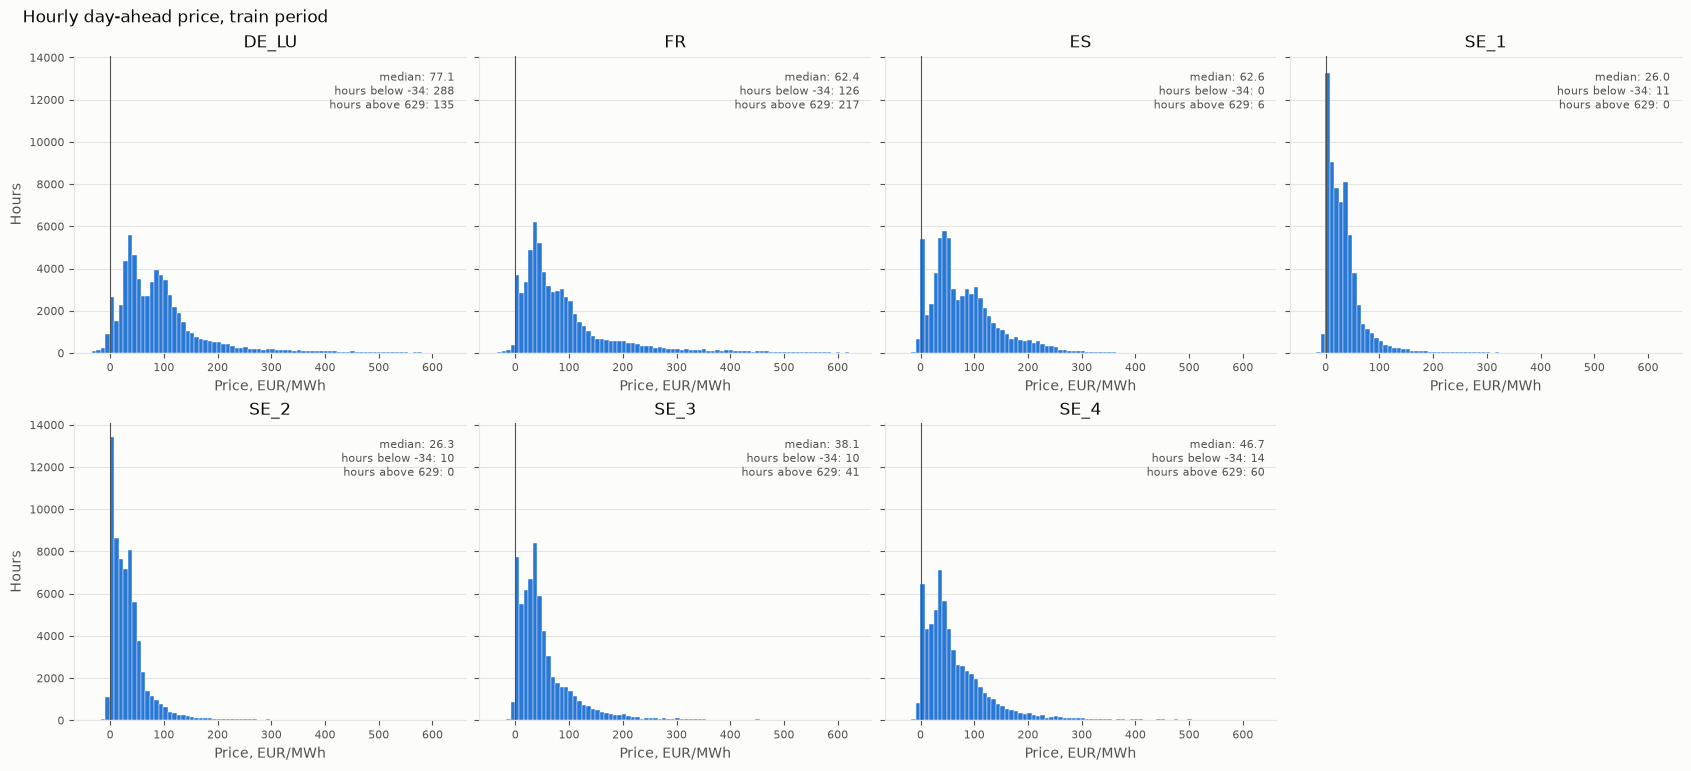

In [2]:
tables, figure = figures.distribution(prices, config)
figures.print_tables(tables)

**Finding.** The price is skewed to the right and has long tails on both sides, in every zone. The Swedish zones are cheaper and more skewed.

- DE_LU has a median of 77.10 and a mean of 94.86. Its 1% quantile is -11.57 and its 99% quantile 475.36. The lowest price is -500.00 and the highest 936.28.
- FR has the longest upper tail: a maximum of 2987.78 on 2022-04-04 at 08:00, with a 99% quantile of 510.00. Its skew is 3.03.
- ES is the narrowest of these three: from -15.00 to 700.00, with a skew of 1.45.
- The Swedish level rises from north to south. The median is 25.99 in SE_1, 26.29 in SE_2, 38.10 in SE_3 and 46.66 in SE_4. The mean is 34.84, 35.15, 56.73 and 68.89.
- SE_1 and SE_2 are almost the same: both have their maximum of 590.00 on 2022-12-14 at 17:00. SE_3 and SE_4 share a maximum of 799.97 on 2022-08-30 at 19:00.
- The Swedish zones are the most skewed: 4.07, 4.01, 3.52 and 3.07. Their 75% quantile is 44.29 in SE_1 and their 99% quantile 211.19.
- Their lowest prices are mild beside DE_LU and FR: -74.11 in SE_1 and -60.04 in SE_2, SE_3 and SE_4.
- The 5% quantile is close to zero in all seven zones, between 0.84 (ES) and 3.09 (FR). Prices at and below zero are part of the target.
- So the project uses no log transform and no MAPE. Both break at zero and below.
- The histogram covers -33.77 to 629.38, the 0.1% and 99.9% quantiles of the prices of all seven zones together. It leaves out 288 hours below and 135 above in DE_LU, 126 and 217 in FR, and 0 and 6 in ES. In the Swedish zones it leaves out 10 to 14 hours below, none above in SE_1 and SE_2, 41 above in SE_3 and 60 in SE_4.
- The DE_LU histogram has two humps. Guess: the lower one is the years 2019 and 2020 and the upper one the years from 2023. Section 4 shows the level per year.

## 2. Price by hour of day


Median price
      DE_LU    FR    ES  SE_1  SE_2  SE_3  SE_4
hour                                           
0     78.22 64.97 75.20 20.82 21.04 29.63 36.10
1     72.91 56.83 67.83 19.98 20.25 27.45 34.05
2     70.45 52.58 63.11 19.20 19.74 26.27 32.23
3     69.06 45.11 60.00 19.19 19.42 26.04 31.82
4     70.00 42.47 58.45 19.77 20.07 27.26 33.56
5     75.01 48.52 60.03 22.67 22.85 31.59 37.59
6     85.26 60.39 68.41 25.91 26.04 38.20 46.95
7     93.01 75.26 80.20 29.20 29.27 45.60 58.73
8     94.08 80.60 78.43 31.21 31.74 50.73 62.14
9     81.15 71.85 65.00 31.23 31.45 47.97 57.61
10    69.13 61.14 55.85 29.94 30.53 44.28 51.47
11    59.96 55.10 52.20 28.99 29.26 41.97 47.20
12    54.37 52.64 50.53 28.01 28.35 40.02 43.88
13    49.16 47.01 49.85 26.95 27.20 38.17 41.97
14    49.93 45.98 47.59 26.43 26.66 37.40 41.25
15    55.41 46.53 46.40 26.78 26.97 38.47 43.09
16    67.84 51.15 48.35 27.88 28.12 41.19 47.95
17    83.96 62.22 53.30 30.06 30.03 46.91 58.94
18    99.98 77.59 63.37 30

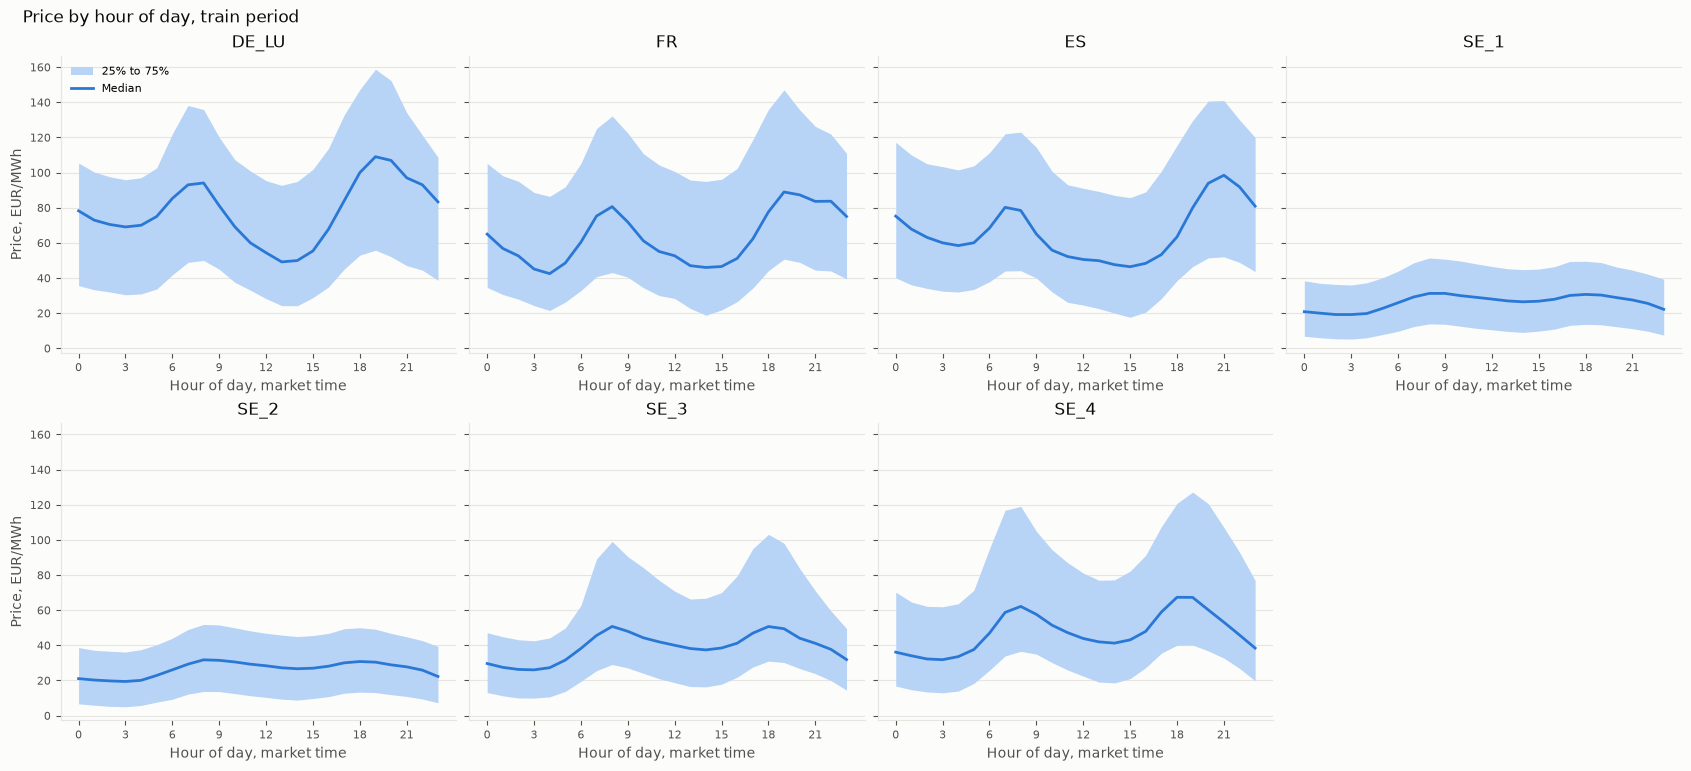

In [3]:
tables, figure = figures.by_hour(prices, config)
figures.print_tables(tables)

**Finding.** All seven zones have a morning peak and an evening peak with a dip between them. The dip is deep in DE_LU, FR and ES and shallow in the north of Sweden.

- DE_LU: the median is 94.08 at hour 8, falls to 49.16 at hour 13 and rises to 109.03 at hour 19.
- FR: 80.60 at hour 8, 45.98 at hour 14 and 88.94 at hour 19. Its lowest median is at night, 42.47 at hour 4.
- ES: the evening peak comes later, 98.47 at hour 21. The low is 46.40 at hour 15.
- SE_4 has the same shape at a lower level: 62.14 at hour 8, 41.25 at hour 14 and 67.34 at hour 18. SE_3 has 50.73, 37.40 and 50.68.
- SE_1 and SE_2 are flat by comparison. SE_1 has 31.21 at hour 8, 26.43 at hour 14 and 30.64 at hour 18.
- In all four Swedish zones the lowest median is at night, at hour 3: 19.19, 19.42, 26.04 and 31.82.
- The spread within one hour is larger than the difference between hours. In DE_LU at hour 19 the middle half of the prices runs from 55.82 to 158.85. In SE_1 at hour 8 it runs from 13.86 to 51.37. The band mixes all years, so it also carries the level changes of section 4.
- Hour 2 has 2729 prices and every other hour 2730. On a 23-hour day hour 2 does not exist, and on a 25-hour day it counts twice.
- Guess: the midday dip comes from solar output. EDA 2 compares the price with the solar forecast for DE_LU, FR and ES. The Swedish zones have no solar forecast in the data, so the guess cannot be tested for them.

## 3. Price by weekday


Median price
         DE_LU    FR    ES  SE_1  SE_2  SE_3  SE_4
weekday                                           
Mon      80.14 65.00 66.40 29.04 29.24 42.87 52.74
Tue      84.06 69.92 73.05 29.37 29.70 43.88 55.98
Wed      83.75 70.00 69.77 27.92 28.38 42.28 54.48
Thu      82.98 68.81 69.00 28.06 28.04 40.53 50.70
Fri      80.80 68.67 67.60 26.42 26.75 38.45 47.78
Sat      65.91 52.33 53.69 20.89 20.98 29.34 36.12
Sun      52.41 43.74 47.58 20.70 21.07 30.02 34.96

25% quantile of the price
         DE_LU    FR    ES  SE_1  SE_2  SE_3  SE_4
weekday                                           
Mon      42.08 35.90 39.04 11.60 11.69 23.41 30.04
Tue      43.99 38.71 41.69 12.94 12.85 24.63 31.80
Wed      44.48 38.51 41.03 11.49 11.11 23.72 31.35
Thu      42.91 37.87 40.53 10.47 10.24 21.34 28.28
Fri      42.05 37.44 39.05 11.00 10.57 20.17 26.26
Sat      31.07 28.29 30.29  6.90  6.80 12.75 15.61
Sun      21.98 18.43 23.54  6.00  5.83 10.34 12.79

75% quantile of the price
         DE_LU

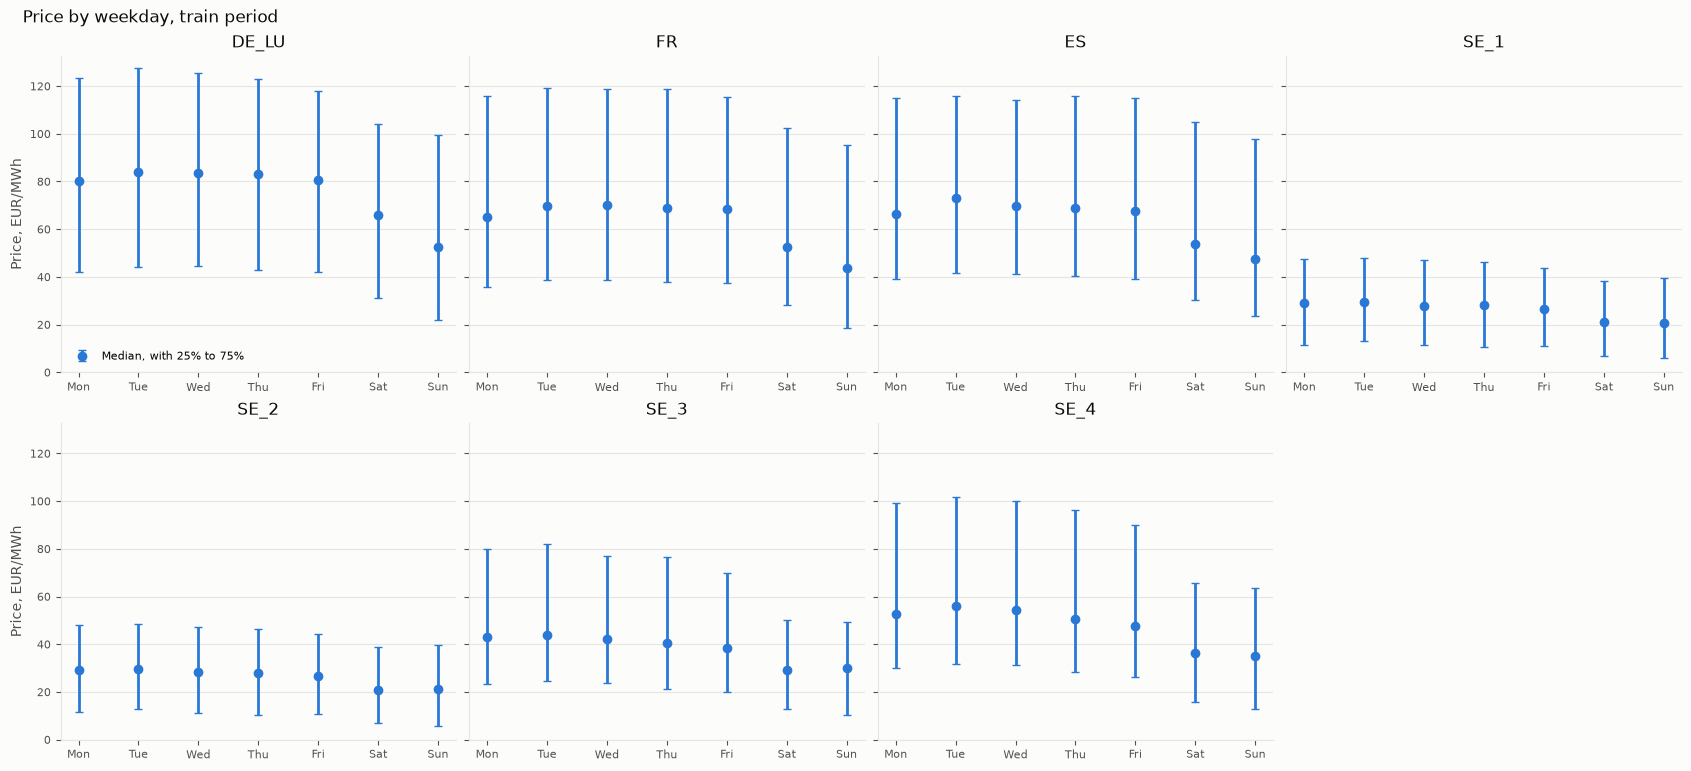

In [4]:
tables, figure = figures.by_weekday(prices, config)
figures.print_tables(tables)

**Finding.** Monday to Friday are alike, and the weekend is cheaper, in every zone.

- DE_LU: the weekday medians lie between 80.14 and 84.06. Saturday is 65.91 and Sunday 52.41.
- FR: 65.00 to 70.00 on weekdays, 52.33 on Saturday and 43.74 on Sunday.
- ES: 66.40 to 73.05 on weekdays, 53.69 on Saturday and 47.58 on Sunday.
- SE_1: 26.42 to 29.37 on weekdays, 20.89 on Saturday and 20.70 on Sunday. SE_2 is nearly the same: 26.75 to 29.70, then 20.98 and 21.07.
- SE_3: 38.45 to 43.88 on weekdays, 29.34 on Saturday and 30.02 on Sunday. SE_4: 47.78 to 55.98, then 36.12 and 34.96.
- In DE_LU, FR and ES Sunday is clearly cheaper than Saturday. In the Swedish zones the two days are about equal.
- The price follows a weekly cycle. That supports the seasonal naive baseline, which takes the same hour seven days earlier, and weekday features for LightGBM.
- Public holidays are not separated here. EDA 2 compares holidays with working days (`notebooks/01_eda_drivers.ipynb`, section 6).
- Sunday has 9359 hours and every other weekday 9360, because the clock changes fall on Sundays.

## 4. Mean price by year and month


Mean price per year (rows) and month (columns), DE_LU
         1      2      3      4      5      6      7      8      9      10     11     12
2019  49.39  42.82  30.63  36.96  37.84  32.52  39.69  36.85  35.75  36.94  41.00  31.97
2020  35.03  21.92  22.49  17.09  17.60  26.18  30.06  34.86  43.69  33.97  38.79  43.52
2021  52.81  48.70  47.16  53.61  53.35  74.08  81.37  82.70 128.37 139.49 176.15 221.06
2022 167.73 128.80 252.01 165.73 177.48 218.03 315.00 465.18 346.12 152.60 173.63 251.62
2023 117.83 128.31 102.52 100.74  81.72  94.76  77.61  94.32 100.72  87.38  91.12  68.52
2024  76.57  61.34  64.70  62.36  67.21  72.89  67.70  82.05  78.31  86.10 113.91 108.32
2025 114.14 128.52  94.73  77.94  67.34  63.99  87.80  76.99  83.51  84.40 101.88  93.47
2026 110.09  96.58  99.29  78.52  97.54  96.46      -      -      -      -      -      -

Mean price per year (rows) and month (columns), FR
         1      2      3      4      5      6      7      8      9      10     11     12
201

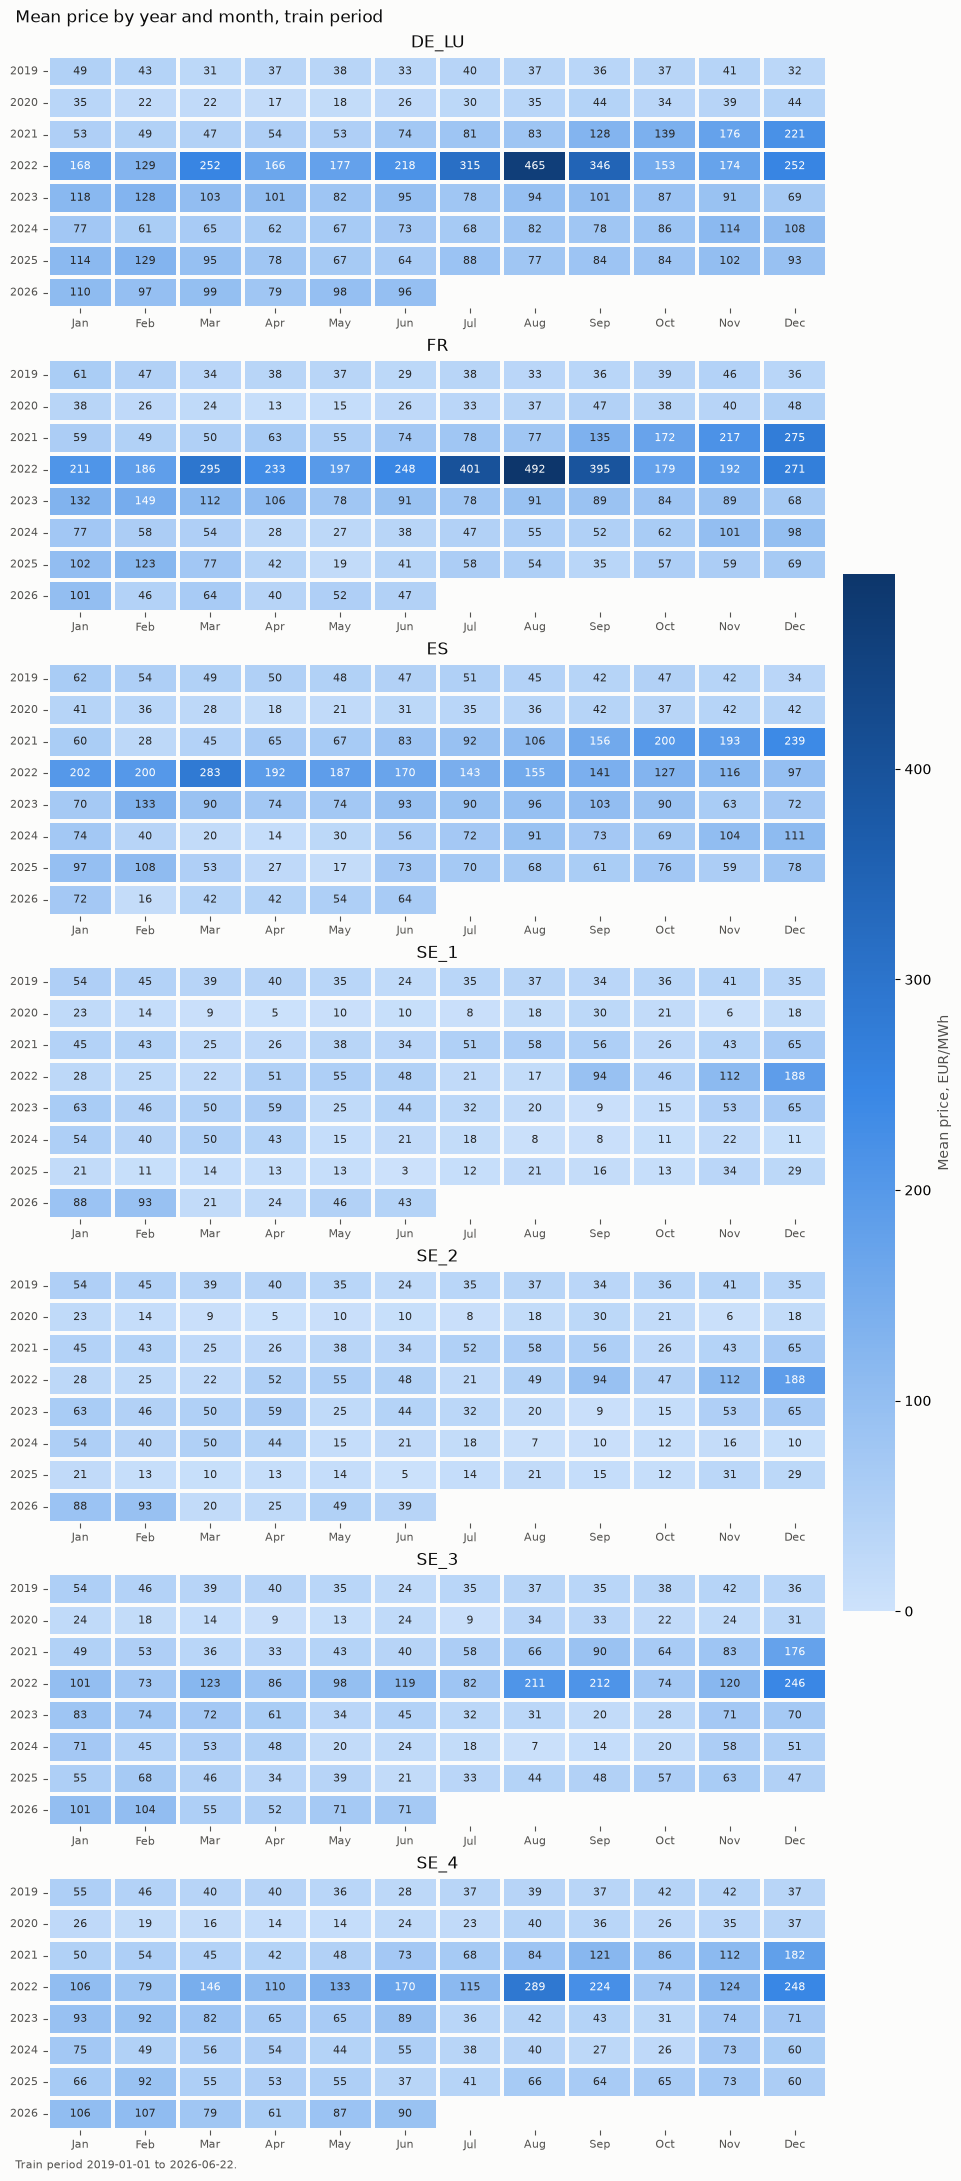

In [5]:
tables, figure = figures.by_month_year(prices, config)
figures.print_tables(tables)

**Finding.** The level moves far more between years than between the months of one year. The north of Sweden did not follow the continental peak of summer 2022.

- DE_LU: the monthly mean runs from 17.09 in April 2020 to 465.18 in August 2022.
- FR peaks at 492.49 in August 2022. ES peaks earlier and lower, at 283.39 in March 2022.
- No month is high or low in every year. In DE_LU, January is 35.03 in 2020, 167.73 in 2022 and 110.09 in 2026.
- From 2024 the spring months are low in FR and ES. FR has 28.23 and 27.17 in April and May 2024 and 19.38 in May 2025. ES has 13.67 in April 2024 and 16.93 in May 2025.
- In 2019 the four Swedish zones are level in every month. January 2019 has 53.50, 53.50, 54.37 and 54.91.
- SE_3 and SE_4 follow the peak of 2022: 211.40 and 289.28 in August 2022, and 245.84 and 248.06 in December 2022.
- SE_1 and SE_2 do not. SE_1 has 21.34 in July and 17.33 in August 2022. Both peak in December 2022, at 188.24 and 188.31.
- The north has very low months since 2024: SE_1 has 7.68 in August 2024 and 2.77 in June 2025. January and February 2026 are high again in all four zones: 87.91 and 92.92 in SE_1, 105.71 and 106.59 in SE_4.
- A model trained on all years sees very different price levels, in every zone. This notebook only states the level. The 2022 regime is analysed in EDA 2.
- 2026 covers 1 January to 22 June, so its June value is the mean of 22 days.

## 5. Spikes

Rule (DECISIONS entry 38): an hour is a spike when its price is above the mean of the 672 hours (28 days) before it plus 3 standard deviations of those hours. Only upward spikes count. The first 672 hours of 2019 have no full window and are not judged. Both numbers are in the config under `eda`. They are conventions and were not tuned.


Summary
       hours_judged  hours_flagged  share_percent  days_flagged
DE_LU         64847            486           0.75           194
FR            64847            493           0.76           167
ES            64847            305           0.47           108
SE_1          64847           1684           2.60           258
SE_2          64847           1708           2.63           262
SE_3          64847           1130           1.74           318
SE_4          64847            798           1.23           275

Hours per year
      DE_LU   FR  ES  SE_1  SE_2  SE_3  SE_4
year                                        
2019     11   15   0    45    45    64    63
2020     56   70   1   166   166   208   116
2021     55   69  55   306   314   215   101
2022    101  171  77   329   348   129   107
2023     33   27   7   228   228   137    99
2024     89   47  63   129   139   165   159
2025    100   66  44   367   361   160   111
2026     41   28  58   114   107    52    42

Hours per mo

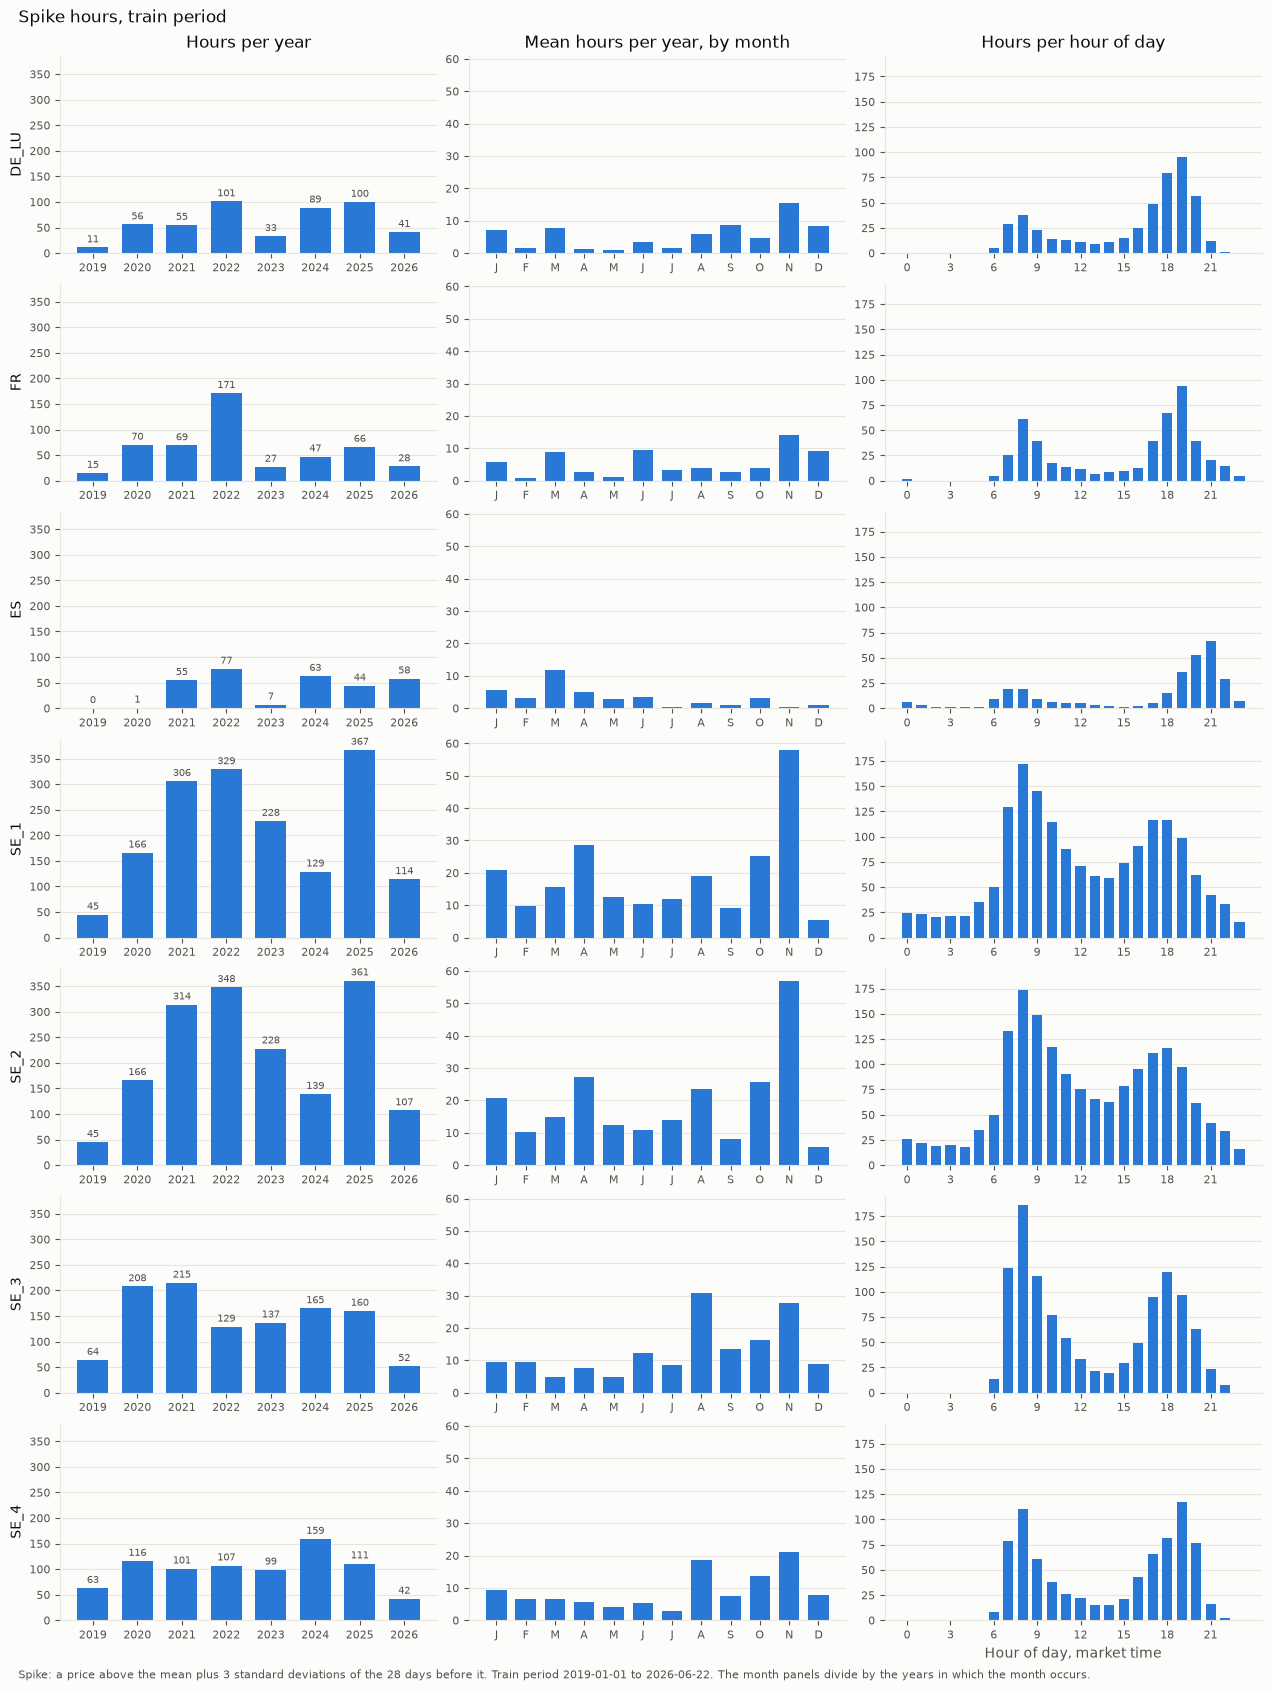

In [6]:
tables, figure = figures.spikes(prices, config)
figures.print_tables(tables)

**Finding.** Spikes are rare in DE_LU, FR and ES and more frequent under the same rule in the Swedish zones. They fall on the morning and evening peaks.

- The rule flags 486 of 64847 judged hours in DE_LU (0.75%), 493 in FR (0.76%) and 305 in ES (0.47%). They fall on 194, 167 and 108 delivery days.
- In the Swedish zones it flags 1684 hours in SE_1 (2.60%), 1708 in SE_2 (2.63%), 1130 in SE_3 (1.74%) and 798 in SE_4 (1.23%), on 258, 262, 318 and 275 delivery days.
- Guess: the Swedish price is low and quiet for long stretches, so the mean and the standard deviation of the 28 days before an hour are small and a moderate price already passes the threshold. The rule measures a jump against the recent level, not a high price in EUR.
- By year in DE_LU, FR and ES the most spike hours are in 2022: 101, 171 and 77. But 2024 and 2025 have 89 and 100 in DE_LU, so the rule does not only mark the crisis year.
- By year in Sweden: SE_1 has 367 spike hours in 2025 and 329 in 2022. SE_3 is highest in 2021 with 215, SE_4 in 2024 with 159.
- By hour: DE_LU has 95 spike hours at hour 19 and none from hour 0 to hour 5. FR has 94 at hour 19 and 61 at hour 8. ES is later, with 67 at hour 21.
- In Sweden the morning counts most. SE_1 has 172 spike hours at hour 8 and 117 at hours 17 and 18. SE_3 has 186 at hour 8 and 120 at hour 18. SE_4 has 110 at hour 8 and 117 at hour 19. SE_1 and SE_2 also have spikes at night, 24 and 26 at hour 0. SE_3 and SE_4 have none from hour 0 to hour 5.
- The month panel shows the mean per year, because January to June occur in eight years of the train set and July to December in seven. DE_LU has 15.43 spike hours per year in November and 0.88 in May. FR has 14.00 in November. ES is highest in March, with 11.75.
- November is the highest month in SE_1 and SE_2 too, with 58.00 and 57.00 hours per year, and in SE_4 with 21.00. SE_3 is highest in August, with 30.71.
- A part month counts as a whole one in that mean. June 2026 ends on the 22nd, and January 2019 is judged only after its first 28 days.
- Guess: these are hours of high demand with little wind and solar. EDA 2 looks at the drivers.

## 6. Negative prices


Summary
       hours_judged  hours_flagged  share_percent  days_flagged  hours_at_zero
DE_LU         65519           2346           3.58           417            191
FR            65519           1616           2.47           311            530
ES            65519           1428           2.18           230           1002
SE_1          65519           1654           2.52           259            192
SE_2          65519           1949           2.97           286            210
SE_3          65519           1539           2.35           259            179
SE_4          65519           1509           2.30           262            157

Hours per year
      DE_LU   FR   ES  SE_1  SE_2  SE_3  SE_4
year                                         
2019    211   27    0     0     0     0     0
2020    298  102    0     9     9     9    10
2021    139   64    0    12    12    12    12
2022     69    4    0    29    29    29    29
2023    301  147    0   434   434   429   368
2024    457  352  247

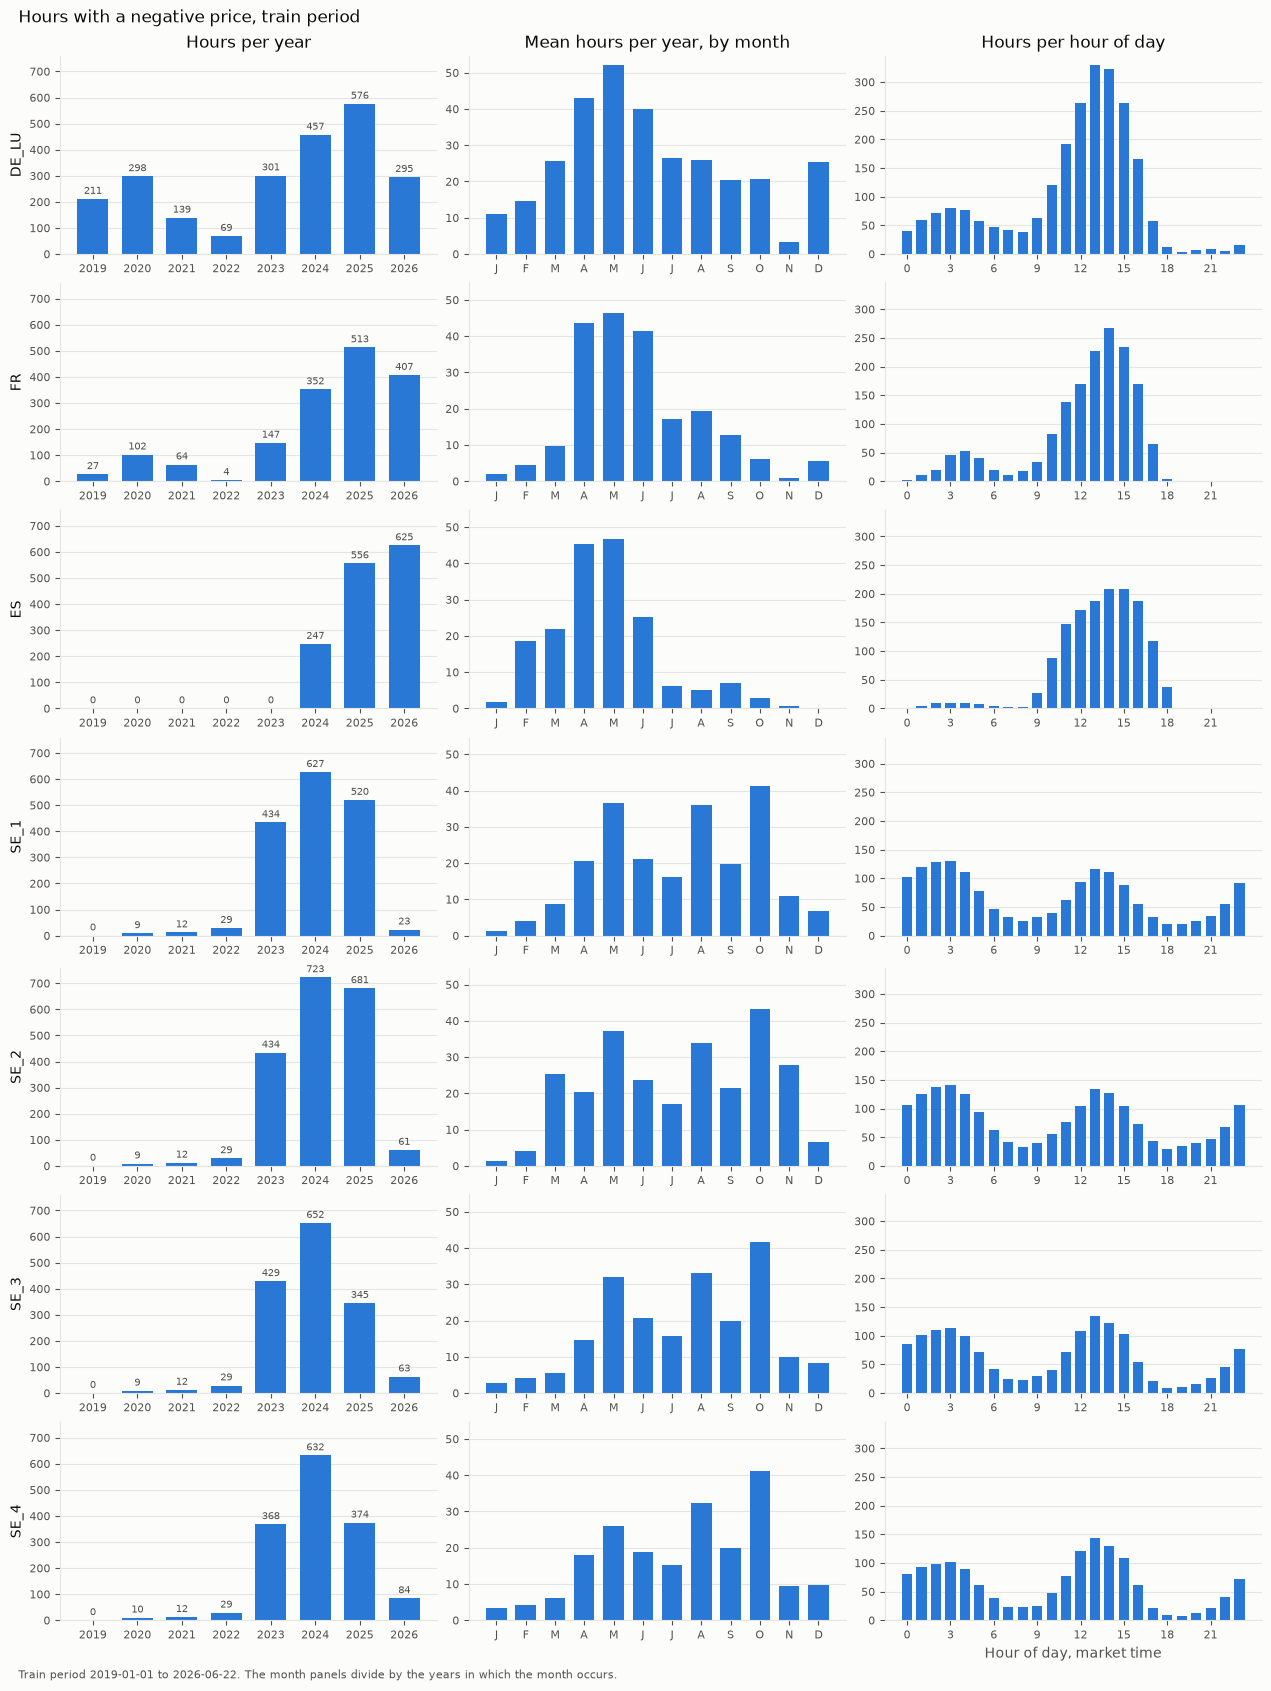

In [7]:
tables, figure = figures.negative_prices(prices, config)
figures.print_tables(tables)

**Finding.** Negative prices are common and growing in every zone. In DE_LU, FR and ES they occur around midday in spring. In Sweden they began in 2023 and occur at night as well as at midday.

- DE_LU has 2346 hours below zero (3.58% of the train hours), FR 1616 (2.47%) and ES 1428 (2.18%). They fall on 417, 311 and 230 delivery days.
- The Swedish zones have 1654 (2.52%), 1949 (2.97%), 1539 (2.35%) and 1509 (2.30%), on 259, 286, 259 and 262 delivery days.
- The count grows. DE_LU: 211 in 2019 and 576 in 2025. FR: 27 in 2019 and 513 in 2025. ES had none before 2024, then 247, 556 and already 625 in 2026 up to 22 June.
- Sweden had none in 2019 and at most 29 a year up to 2022. Then SE_1 has 434 in 2023, 627 in 2024 and 520 in 2025. SE_2 has 723 in 2024 and 681 in 2025. In 2026 up to 22 June the counts are low: 23, 61, 63 and 84.
- By hour in DE_LU, FR and ES: DE_LU has 329 at hour 13, FR 267 at hour 14 and ES 208 at hours 14 and 15. From hour 19 to hour 22 none of the three has more than 9.
- By hour in Sweden there are two groups. SE_1 has 130 negative hours at hour 3 and 117 at hour 13, and its fewest, 20, at hours 18 and 19. SE_4 has 101 at hour 3 and 143 at hour 13.
- By month, as a mean per year: May is highest in DE_LU, FR and ES, with 52.00, 46.38 and 46.62 hours. November is lowest in DE_LU and FR, with 3.29 and 0.86.
- In Sweden October is highest in all four zones, with 41.14, 43.29, 41.71 and 41.14 hours per year. May and August follow: 36.50 and 36.00 in SE_1.
- The mean is used because January to June occur in eight years of the train set and July to December in seven. June 2026 ends on the 22nd and still counts as a whole month.
- Prices of exactly zero come on top: 191 hours in DE_LU, 530 in FR and 1002 in ES, and 192, 210, 179 and 157 in the Swedish zones.
- The lowest prices are -500.00 in DE_LU (2023-07-02 at 14:00), -496.86 in FR (2026-05-01 at 13:00) and -15.00 in ES. SE_1 has -74.11 on 2025-10-02 at 19:00. SE_2, SE_3 and SE_4 share -60.04 on 2023-07-16 at 14:00.
- The recent train years differ from the early ones, most of all in ES and in Sweden. The validation and test sets come after these recent years, so a model must handle prices at and below zero.
- Guess: in DE_LU, FR and ES these are hours with much solar output and low demand. EDA 2 checks this against the forecasts. Guess: the night hours in Sweden are hours of much wind and low demand. EDA 2 compares the Swedish negative hours with the wind forecast.

## Not in this notebook

EDA 2 covers the price against load, wind and solar, hourly against 15-minute prices, the 2022 regime and holidays for all seven zones, and a comparison of the four Swedish zones from north to south.